# Phase unwrapping with Kamui

This notebook unwraps synthetic 2-D phase images with Kamui and compares the results with
scikit-image's `unwrap_phase`, the quality-guided path follower of Herráez et al. (2002).
It then shows what plain path following has no answer for: per-pixel weights, missing data,
and a choice of solvers with a report on each solve.

Unwrapping recovers the phase only up to one constant multiple of $2\pi$. Each figure therefore
shows the true phase, the wrapped input, and an error map per method: the number of whole
periods by which each pixel misses the truth, after removing the most common offset.
White pixels are correct, and gray ones are NaN.

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from skimage import color, data, exposure, img_as_float
from skimage.restoration import unwrap_phase

import kamui

# Seeded, so re-executing the notebook reproduces its figures.
rng = np.random.default_rng(0)

In [2]:
def cycle_errors(unwrapped, truth):
    """Whole periods by which each pixel of `unwrapped` misses `truth`.

    The most common offset counts as correct. NaN pixels stay NaN.
    """
    cycles = np.round((unwrapped - truth) / (2 * np.pi))
    values, counts = np.unique(cycles[~np.isnan(cycles)], return_counts=True)
    return cycles - values[counts.argmax()]


def n_errors(unwrapped, truth):
    """Count the pixels that land on the wrong multiple of 2π."""
    return int(np.sum(np.abs(cycle_errors(unwrapped, truth)) > 0.5))


def compare(truth, wrapped, results):
    """Plot the true and wrapped phase, then the cycle errors of each result."""
    error_cmap = plt.get_cmap("RdBu_r").with_extremes(bad="0.6")
    n = 2 + len(results)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.4), layout="constrained")
    for ax in axes:
        ax.set_axis_off()
    axes[0].imshow(truth, cmap="gray")
    axes[0].set_title("True phase")
    axes[1].imshow(wrapped, cmap="twilight", vmin=-np.pi, vmax=np.pi)
    axes[1].set_title("Wrapped")
    for ax, (name, unwrapped) in zip(axes[2:], results.items()):
        im = ax.imshow(cycle_errors(unwrapped, truth), cmap=error_cmap, vmin=-2, vmax=2)
        ax.set_title(f"{name}: {n_errors(unwrapped, truth)} wrong")
    fig.colorbar(im, ax=axes[2:], ticks=range(-2, 3), shrink=0.8, label="error (periods)")
    plt.show()

## Plane wave

`kamui.wrap_difference` wraps a phase into $[-\pi, \pi)$, and `kamui.unwrap_dimensional`
unwraps a 2-D or 3-D array. Without noise, both methods recover the plane exactly.

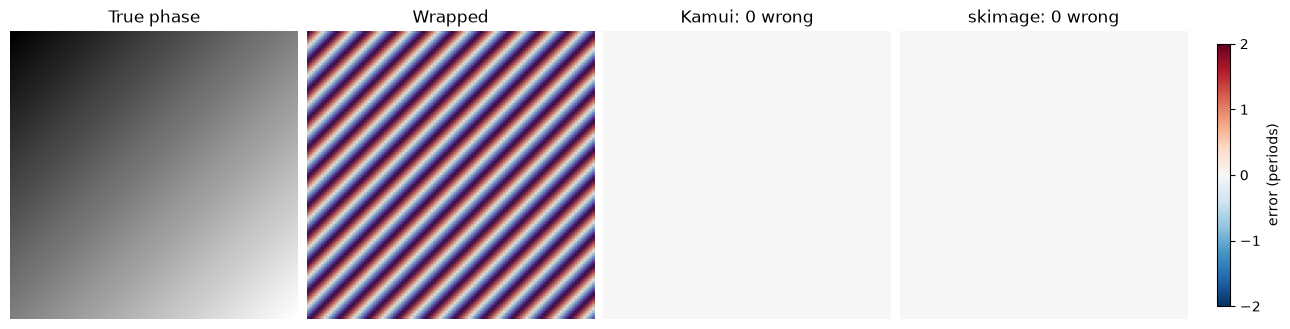

In [3]:
N = 100
yy, xx = np.mgrid[0:N, 0:N]
plane_wave = 0.2 * np.pi * (xx + yy)
wrapped_plane_wave = kamui.wrap_difference(plane_wave)

compare(
    plane_wave,
    wrapped_plane_wave,
    {
        "Kamui": kamui.unwrap_dimensional(wrapped_plane_wave),
        "skimage": unwrap_phase(wrapped_plane_wave),
    },
)

## Noise

Noise with a standard deviation of 0.15 periods creates residues: cycles of four pixels whose
wrapped differences do not sum to zero. Kamui places the $2\pi$ corrections that cancel them with
the least total cost over the whole image, while path following decides one pixel at a time.

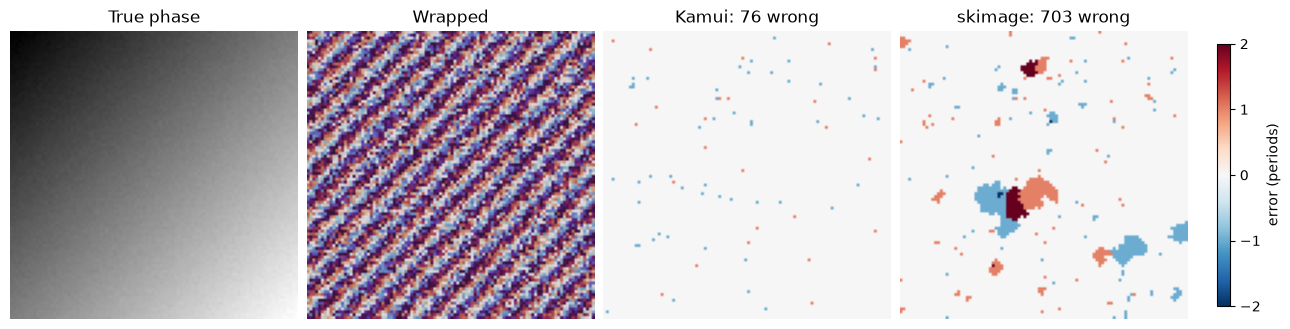

In [4]:
noisy_plane_wave = plane_wave + rng.normal(0, 0.15 * 2 * np.pi, plane_wave.shape)
wrapped_noisy_plane_wave = kamui.wrap_difference(noisy_plane_wave)

compare(
    noisy_plane_wave,
    wrapped_noisy_plane_wave,
    {
        "Kamui": kamui.unwrap_dimensional(wrapped_noisy_plane_wave),
        "skimage": unwrap_phase(wrapped_noisy_plane_wave),
    },
)

## Shear

Two ramps meet head to head along the middle row, where the phase jumps by up to 60 rad.
The jump changes by less than $\pi$ from one column to the next, and Kamui recovers the seam
exactly. Path following unwraps each half correctly but sets the halves a whole number of periods
apart.

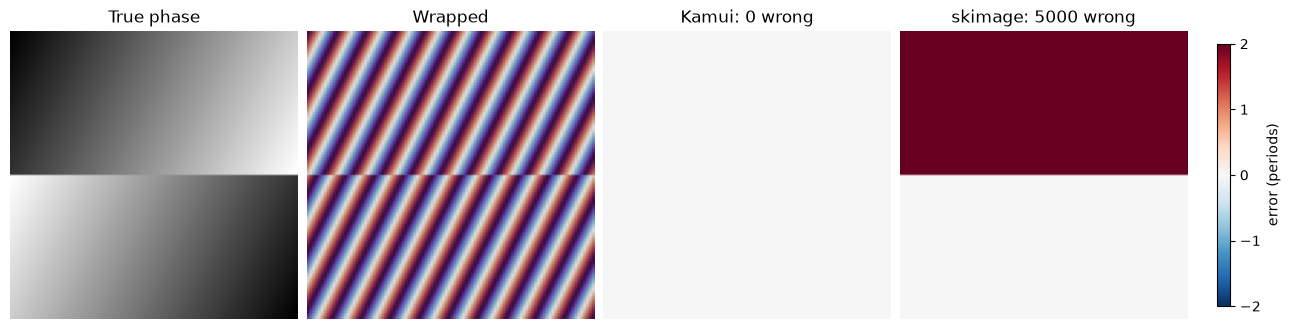

In [5]:
yy2, xx2 = np.mgrid[0:50, 0:100]
ramp = xx2 / 1.6 + yy2 / 3.2
shear = np.concatenate([ramp, ramp[::-1, ::-1]])
wrapped_shear = kamui.wrap_difference(shear)

compare(
    shear,
    wrapped_shear,
    {
        "Kamui": kamui.unwrap_dimensional(wrapped_shear),
        "skimage": unwrap_phase(wrapped_shear),
    },
)

## Missing data

A Gaussian of height $10\pi$ with its top-left quadrant cut away has cliffs more than $\pi$ high
along the cut, and both methods misplace a few pixels where the cliffs meet near the peak. When you
know where the data is invalid, set it to NaN: `unwrap_dimensional` drops every edge that touches a
NaN pixel, unwraps the rest, and returns NaN there. Masked like that, the remaining surface comes
back exactly.

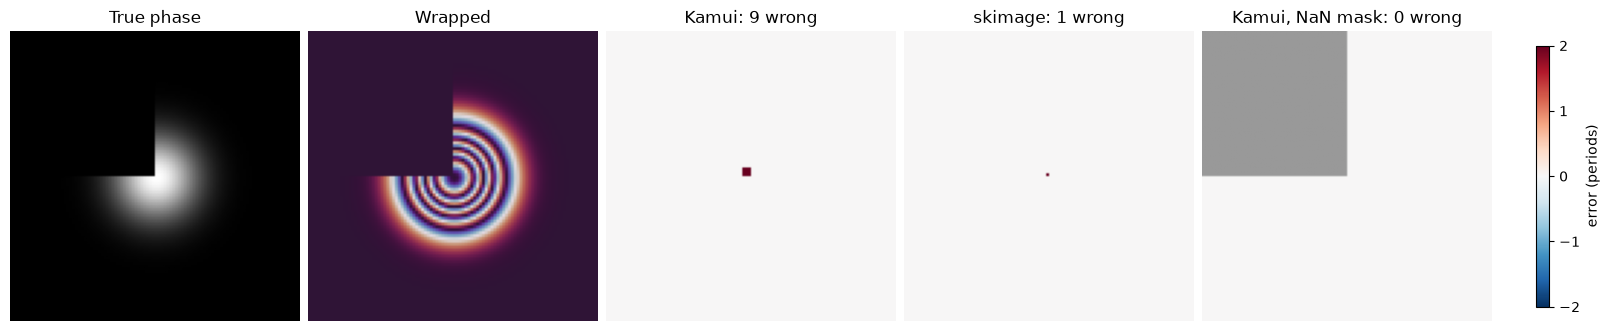

In [6]:
gauss = 10 * np.pi * np.exp(-0.5 * ((xx - N / 2) ** 2 + (yy - N / 2) ** 2) / (N / 10) ** 2)
gauss[: N // 2, : N // 2] = 0
wrapped_gauss = kamui.wrap_difference(gauss)

masked_gauss = wrapped_gauss.copy()
masked_gauss[: N // 2, : N // 2] = np.nan
unwrapped_masked_gauss = kamui.unwrap_dimensional(masked_gauss)

compare(
    gauss,
    wrapped_gauss,
    {
        "Kamui": kamui.unwrap_dimensional(wrapped_gauss),
        "skimage": unwrap_phase(wrapped_gauss),
        "Kamui, NaN mask": unwrapped_masked_gauss,
    },
)

## Weights

In practice, the noise varies across the image, and a quality map such as InSAR coherence says
where. Here a vertical band of low coherence crosses the plane wave. Per-pixel `weights` make
corrections cheap where coherence is low, which steers them into the band. Each edge gets the sum
of its two pixels' weights.

LEMON's network simplex needs integer weights, and Kamui does not round them for you, so scale
and round them yourself. Fractional weights work too, but HiGHS solves them several times slower.
`return_info=True` also returns the solver's report, which names the solver that ran.

integer weights: lemon, fractional weights: highs


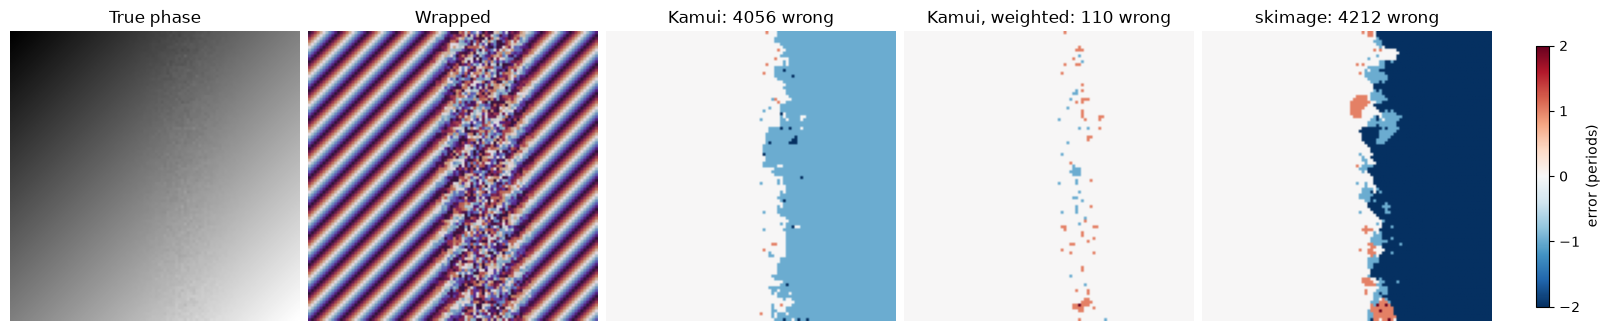

In [7]:
coherence = 1 - 0.85 * np.exp(-0.5 * ((xx - 60) / 8) ** 2)
noise_std = 0.25 * 2 * np.pi * (1 - coherence) / 0.85
weights = np.round(coherence * 100)


def banded(seed):
    """Draw the plane wave with noise that grows as coherence drops."""
    return plane_wave + np.random.default_rng(seed).normal(0, noise_std)


banded_wave = banded(1)
wrapped_banded_wave = kamui.wrap_difference(banded_wave)
unweighted = kamui.unwrap_dimensional(wrapped_banded_wave)
weighted, info = kamui.unwrap_dimensional(wrapped_banded_wave, weights=weights, return_info=True)
_, fractional_info = kamui.unwrap_dimensional(
    wrapped_banded_wave, weights=coherence, return_info=True
)
print(f"integer weights: {info.solver}, fractional weights: {fractional_info.solver}")

compare(
    banded_wave,
    wrapped_banded_wave,
    {
        "Kamui": unweighted,
        "Kamui, weighted": weighted,
        "skimage": unwrap_phase(wrapped_banded_wave),
    },
)

Pixels inside the band are mostly lost to noise either way. What the weights decide is how the two
sides connect across it: without them, some noise draws leave a whole side one period off.
Over a dozen draws:

In [8]:
wrong = {"Kamui": [], "Kamui, weighted": []}
for seed in range(1, 13):
    truth = banded(seed)
    wrapped = kamui.wrap_difference(truth)
    wrong["Kamui"].append(n_errors(kamui.unwrap_dimensional(wrapped), truth))
    wrong["Kamui, weighted"].append(
        n_errors(kamui.unwrap_dimensional(wrapped, weights=weights), truth)
    )

for name, counts in wrong.items():
    sides_off = sum(count > N * N / 4 for count in counts)
    print(f"{name}: {np.mean(counts):.0f} wrong pixels on average, a side off in {sides_off} of 12")

Kamui: 1115 wrong pixels on average, a side off in 3 of 12
Kamui, weighted: 429 wrong pixels on average, a side off in 1 of 12


## Choosing a solver

The cat's fur is a harder test: neighbouring pixels differ by up to $2.25\pi$, so no unwrapper
recovers it exactly. The default solver is the network-programming ILP, which LEMON solves on
2-D grids. `method="gc"` selects PUMA instead (Bioucas-Dias and Valadão, 2007), which minimizes
a $p$-norm of the phase differences with graph cuts and needs `pip install kamui[extra]`.

skimage took 0.04 s
Kamui ILP took 0.23 s
Kamui PUMA took 1.00 s


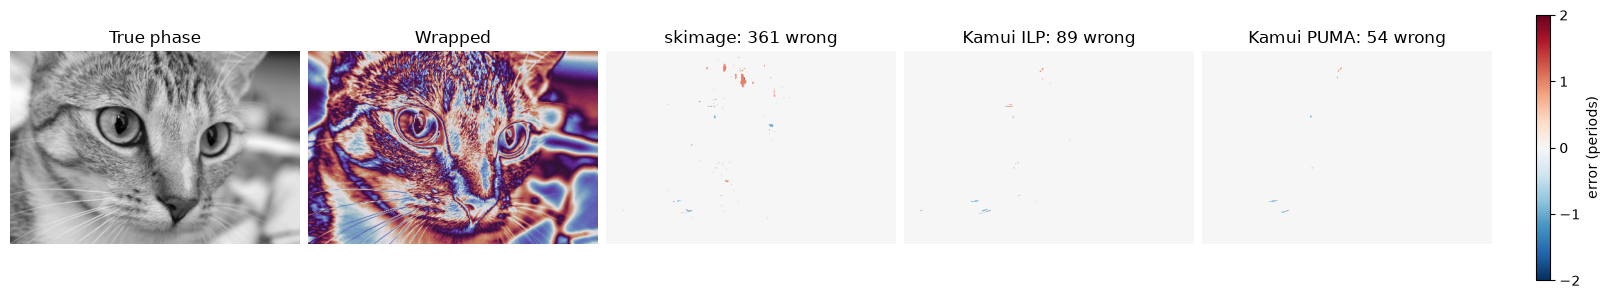

In [9]:
gray_cat = color.rgb2gray(img_as_float(data.chelsea()))
cat = exposure.rescale_intensity(gray_cat, out_range=(0, 4 * np.pi))
wrapped_cat = kamui.wrap_difference(cat)

methods = {
    "skimage": lambda: unwrap_phase(wrapped_cat),
    "Kamui ILP": lambda: kamui.unwrap_dimensional(wrapped_cat),
    "Kamui PUMA": lambda: kamui.unwrap_dimensional(wrapped_cat, method="gc"),
}
cat_results = {}
for name, unwrap in methods.items():
    start = perf_counter()
    cat_results[name] = unwrap()
    print(f"{name} took {perf_counter() - start:.2f} s")

compare(cat, wrapped_cat, cat_results)

## Check

CI executes this notebook, so these asserts catch regressions. The noiseless examples must come
back exactly, weights must halve the average error in the banded example, and fewer than 1 % of
the cat's pixels may land on the wrong multiple of $2\pi$.

In [10]:
assert n_errors(kamui.unwrap_dimensional(wrapped_plane_wave), plane_wave) == 0
assert n_errors(kamui.unwrap_dimensional(wrapped_shear), shear) == 0
assert n_errors(unwrapped_masked_gauss, gauss) == 0
assert np.isnan(unwrapped_masked_gauss[: N // 2, : N // 2]).all()
assert info.solver == "lemon" and fractional_info.solver == "highs"
assert np.mean(wrong["Kamui, weighted"]) < np.mean(wrong["Kamui"]) / 2
for name in ("Kamui ILP", "Kamui PUMA"):
    assert n_errors(cat_results[name], cat) < 0.01 * cat.size